# SigLIP-2 — Fakeddit 3-Way Fake News Detection (No Metadata)
**3-Way Classification Only — 2-way and 6-way are cancelled**

## Model: SigLIP-2 (google/siglip-so400m-patch14-384)
- **Task**: 3-way classification — Text + Image only (no metadata)
  - Class 0: True / Authentic
  - Class 1: Fake with True Text (satire, misleading, manipulated)
  - Class 2: Fake with False Text (false connection, imposter)
- **Dataset**: Fakeddit — `3_way_label` column only

## Architecture — Bidirectional Cross-Attention Fusion:
```
img_embed ─→ vision_proj (256-d) ─┬─→ img2txt cross-attention (256-d) ─┐
                                   │                                     │
txt_embed ─→ text_proj  (256-d) ─┴─→ txt2img cross-attention (256-d) ─┤
                                                                         │
              concat [vis_proj, txt_proj, img2txt, txt2img]  1024-d ───┘
                         ↓
              LayerNorm → 512 → 256 → 3
```

## Configuration:
- 5-Fold Cross-Validation (80 / 10 / 10 per fold)
- 10 epochs, early stopping patience=3
- Stochastic Weight Averaging (SWA, last 3 epochs)
- Anti-overfitting: dropout, weight decay, label smoothing

## Classification Scope:
❌ 2-way classification — **CANCELLED**
❌ 6-way classification — **CANCELLED**
❌ Metadata branch     — **NOT USED** (pure text + image)
✅ 3-way classification — **ONLY active mode**


In [6]:
# ── Cell 1: Install Dependencies ─────────────────────────────────────────────
import sys
import subprocess

print("Installing SigLIP and dependencies...\n")

packages = [
    "transformers>=4.40.0",  # SigLIP requires newer transformers
    "pillow",
    "tabulate",
    "scikit-learn",
]

for i, pkg in enumerate(packages, 1):
    print(f"[{i}/{len(packages)}] Installing {pkg}...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

print("\n✓ All packages installed!\n")

# Verify
try:
    from transformers import AutoProcessor, AutoModel
    import torch
    print("✓ Transformers imported successfully")
    print(f"  Version: {__import__('transformers').__version__}")
    print(f"  PyTorch: {torch.__version__}")
except ImportError as e:
    print("✗ Import failed!")
    raise e

Installing SigLIP and dependencies...

[1/4] Installing transformers>=4.40.0...
[2/4] Installing pillow...
[3/4] Installing tabulate...
[4/4] Installing scikit-learn...

✓ All packages installed!

✓ Transformers imported successfully
  Version: 5.0.0
  PyTorch: 2.10.0+cu128


In [7]:
# ── Cell 2: Imports & Configuration ──────────────────────────────────────────
import os, gc, json, random, warnings, copy, math
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim.swa_utils import AveragedModel
from PIL import Image

from transformers import AutoProcessor, AutoModel
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix,
)
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# ══════════════════════ CONFIGURATION ════════════════════════════════════════
SEED          = 42
NUM_SAMPLES   = 6000      # 2000 per class
NUM_CLASSES   = 3         # 3-WAY ONLY  (2-way & 6-way CANCELLED)
NUM_FOLDS     = 5
EPOCHS        = 10
BATCH_SIZE    = 8
LEARNING_RATE = 2e-5
WEIGHT_DECAY  = 1e-2
DROPOUT_RATE  = 0.30
PATIENCE      = 3
DEVICE        = "cuda" if torch.cuda.is_available() else "cpu"

# Fakeddit 3-way label names
LABEL_NAMES = ["True/Authentic", "Fake-TrueText", "Fake-FalseText"]

SIGLIP_MODEL  = "google/siglip-so400m-patch14-384"
OUTPUT_DIR    = "/kaggle/working"

# SWA
USE_SWA      = True
SWA_START_EP = max(EPOCHS - 3, 1)

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

USE_AMP = DEVICE == "cuda"

print(f"Device      : {DEVICE}")
print(f"GPU         : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"Model       : SigLIP-2 SO400M-384")
print(f"Task        : 3-way ONLY  (2-way & 6-way CANCELLED)")
print(f"Metadata    : NONE  (pure text + image fusion)")
print(f"Fusion      : Bidirectional cross-attention  [vis | txt | img2txt | txt2img]")
print(f"SWA         : {'enabled (last 3 epochs)' if USE_SWA else 'disabled'}")
print(f"Config      : {EPOCHS} epochs | {NUM_FOLDS} folds | batch {BATCH_SIZE}")
print("=" * 70)


Device      : cuda
GPU         : Tesla T4
Model       : SigLIP-2 SO400M-384
Task        : 3-way ONLY  (2-way & 6-way CANCELLED)
Metadata    : NONE  (pure text + image fusion)
Fusion      : Bidirectional cross-attention  [vis | txt | img2txt | txt2img]
SWA         : enabled (last 3 epochs)
Config      : 10 epochs | 5 folds | batch 8


In [8]:
# ── Cell 3: Fakeddit Dataset Loader (3-Way, No Metadata) ─────────────────────

def load_fakeddit(n_samples=NUM_SAMPLES):
    """Load Fakeddit 3-way only — no metadata columns required."""
    print("Scanning for Fakeddit dataset...\n")
    for tsv in Path("/kaggle/input").rglob("*.tsv"):
        print(f"Found TSV: {tsv.name}")
        return load_from_tsv(tsv, n_samples)
    for csv_f in Path("/kaggle/input").rglob("*.csv"):
        print(f"Found CSV: {csv_f.name}")
        return load_from_tsv(csv_f, n_samples)
    raise FileNotFoundError(
        "No Fakeddit dataset found!\n"
        "Upload a TSV/CSV with '3_way_label', 'clean_title'/'title', 'id' columns."
    )


def load_from_tsv(file_path, n_samples):
    sep = "\t" if file_path.suffix == ".tsv" else ","
    df  = pd.read_csv(file_path, sep=sep, low_memory=False)
    df.columns = df.columns.str.strip()
    print(f"Columns: {list(df.columns[:10])}...")

    text_col = next((c for c in ["clean_title", "title", "text"] if c in df.columns), None)
    id_col   = "id" if "id" in df.columns else df.columns[0]

    # ── 3-way ONLY ─────────────────────────────────────────────────────────────
    if "3_way_label" not in df.columns:
        raise ValueError(
            f"Missing '3_way_label' column. Found: {list(df.columns)}\n"
            "2-way and 6-way are CANCELLED."
        )
    if not text_col:
        raise ValueError(f"No text column found. Columns: {list(df.columns[:10])}")

    df = df[[id_col, text_col, "3_way_label"]].dropna(subset=["3_way_label"])
    df = df.rename(columns={id_col: "id", text_col: "text", "3_way_label": "label"})
    df["label"] = df["label"].astype(int)
    df = df[df["label"].isin([0, 1, 2])]

    # Clean text
    df["text"] = (
        df["text"].astype(str).str.strip()
        .apply(lambda x: x[:300] if len(x) > 300 else x)
        .replace("", "[No text]")
    )

    # Find images
    img_dir = file_path.parent / "public_image_set"
    if not img_dir.exists():
        for sub in ["public_images", "images", "image_set"]:
            cand = file_path.parent / sub
            if cand.exists():
                img_dir = cand
                break
    if img_dir.exists():
        df["image_path"] = df["id"].apply(lambda x: find_image(x, img_dir))
        df = df[df["image_path"].notna()]
    else:
        df["image_path"] = None
        for cand in file_path.parent.rglob("*"):
            if cand.is_dir():
                sample = list(cand.glob("*.jpg"))[:5] + list(cand.glob("*.jpeg"))[:5]
                if len(sample) >= 3:
                    df["image_path"] = df["id"].apply(lambda x: find_image(x, cand))
                    imgs_found = df["image_path"].notna().sum()
                    if imgs_found > 100:
                        df = df[df["image_path"].notna()]
                        break

    return balance_df(df, n_samples)


def find_image(img_id, img_dir):
    for ext in [".jpg", ".jpeg", ".png", ".gif", ".webp"]:
        p = img_dir / f"{img_id}{ext}"
        if p.exists():
            return str(p)
    return None


def balance_df(df, n_samples):
    """Balance 3 classes equally."""
    if len(df) == 0:
        raise ValueError("No valid 3-way samples found!")
    per_class = n_samples // NUM_CLASSES
    parts = []
    for cls in range(NUM_CLASSES):
        cls_df = df[df["label"] == cls]
        n = min(per_class, len(cls_df))
        parts.append(cls_df.sample(n, random_state=SEED))
        print(f"  Class {cls} ({LABEL_NAMES[cls]:20s}): {n} samples")
    out = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    print(f"\nTotal: {len(out)} samples  ({per_class} per class)")
    return out


print("Fakeddit 3-way loader ready (no metadata)")


Fakeddit 3-way loader ready (no metadata)


In [9]:
# ── Cell 4: SigLIPDataset (3-Way, No Metadata) ───────────────────────────────

class SigLIPDataset(Dataset):
    """
    Dataset for SigLIP-2 text + image — no metadata branch.

    Batch keys: pixel_values, input_ids, attention_mask, labels
    """

    def __init__(self, df, processor, augment=False, training=False):
        self.df          = df.reset_index(drop=True)
        self.processor   = processor
        self.training    = training
        self.placeholder = Image.new("RGB", (384, 384), (127, 127, 127))

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        text  = str(row["text"])
        label = int(row["label"])

        img_path = row.get("image_path")
        try:
            img = Image.open(img_path).convert("RGB") if img_path else self.placeholder
        except Exception:
            img = self.placeholder

        inputs = self.processor(
            text=text, images=img,
            return_tensors="pt", padding="max_length",
            truncation=True, max_length=64,
        )
        inputs = {k: v.squeeze(0) for k, v in inputs.items()}
        inputs["labels"] = torch.tensor(label, dtype=torch.long)
        return inputs


def collate_fn(batch):
    labels = torch.stack([b["labels"] for b in batch])
    result = {"labels": labels}
    for key in batch[0].keys():
        if key != "labels":
            result[key] = torch.stack([b[key] for b in batch])
    return result


print("SigLIPDataset (no metadata) defined")


SigLIPDataset (no metadata) defined


In [10]:
# ── Cell 5: SigLIPClassifier (3-Way, Cross-Attention, No Metadata) ────────────

class SigLIPClassifier(nn.Module):
    """
    Bidirectional cross-attention fusion — 3-WAY OUTPUT.

    1. Vision branch  : SigLIP-2 image encoder  →  vision_proj  (PROJ_DIM)
    2. Text  branch   : SigLIP-2 text encoder   →  text_proj    (PROJ_DIM)
    3. img→txt cross-attention  (PROJ_DIM)
    4. txt→img cross-attention  (PROJ_DIM)

    Fusion: concat [vis, txt, img2txt, txt2img]  =  4 × PROJ_DIM  =  1024-d
            →  LayerNorm  →  512  →  GELU  →  Dropout
            →  256  →  GELU  →  Dropout  →  NUM_CLASSES (3)

    Unfrozen: last 2 vision encoder blocks; text encoder fully frozen.
    """

    PROJ_DIM = 256

    def __init__(self, siglip_model, num_classes=NUM_CLASSES, dropout=DROPOUT_RATE):
        super().__init__()
        self.siglip     = siglip_model
        self.vision_dim = siglip_model.config.vision_config.hidden_size
        self.text_dim   = siglip_model.config.text_config.hidden_size

        # Freeze entire backbone
        for p in self.siglip.parameters():
            p.requires_grad = False

        # Unfreeze last 2 vision encoder blocks
        if hasattr(self.siglip.vision_model, "encoder"):
            for layer in self.siglip.vision_model.encoder.layers[-2:]:
                for p in layer.parameters():
                    p.requires_grad = True

        D = self.PROJ_DIM

        # Modality projections
        self.vision_proj = nn.Sequential(
            nn.Linear(self.vision_dim, D), nn.LayerNorm(D), nn.GELU(), nn.Dropout(0.10))
        self.text_proj = nn.Sequential(
            nn.Linear(self.text_dim,   D), nn.LayerNorm(D), nn.GELU(), nn.Dropout(0.10))

        # Bidirectional cross-attention
        self.img2txt = nn.MultiheadAttention(
            embed_dim=D, num_heads=8, dropout=0.10, batch_first=True)
        self.txt2img = nn.MultiheadAttention(
            embed_dim=D, num_heads=8, dropout=0.10, batch_first=True)
        self.norm_i2t = nn.LayerNorm(D)
        self.norm_t2i = nn.LayerNorm(D)

        # Classifier: [vis, txt, img2txt, txt2img] = 4*D = 1024 → 3
        fused_dim = D * 4
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(dropout),
            nn.Linear(fused_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, 256),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, num_classes),
        )

        for m in (list(self.vision_proj.modules())
                  + list(self.text_proj.modules())
                  + list(self.classifier.modules())):
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total     = sum(p.numel() for p in self.parameters())
        print(f"  SigLIPClassifier (3-way, no metadata): "
              f"{trainable/1e6:.1f}M / {total/1e6:.1f}M params trainable")
        print(f"  Fusion: {fused_dim}-d  "
              f"(vis {D} + txt {D} + img2txt {D} + txt2img {D})  →  {num_classes} classes")

    def forward(self, pixel_values, input_ids, attention_mask=None, **unused):
        out = self.siglip(
            pixel_values=pixel_values,
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True,
        )
        vis = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
        txt = out.text_embeds  / out.text_embeds.norm(dim=-1, keepdim=True)

        p_vis = self.vision_proj(vis)      # (B, D)
        p_txt = self.text_proj(txt)        # (B, D)

        # Cross-attention (unsqueeze to sequence dim=1)
        vis_seq = p_vis.unsqueeze(1)       # (B, 1, D)
        txt_seq = p_txt.unsqueeze(1)       # (B, 1, D)

        i2t_out, _ = self.img2txt(query=vis_seq, key=txt_seq, value=txt_seq)
        t2i_out, _ = self.txt2img(query=txt_seq, key=vis_seq, value=vis_seq)

        p_i2t = self.norm_i2t(vis_seq + i2t_out).squeeze(1)   # (B, D)
        p_t2i = self.norm_t2i(txt_seq + t2i_out).squeeze(1)   # (B, D)

        fused = torch.cat([p_vis, p_txt, p_i2t, p_t2i], dim=-1)   # (B, 4D)
        return self.classifier(fused)


print("SigLIPClassifier (3-way, cross-attention, no metadata) defined")


SigLIPClassifier (3-way, cross-attention, no metadata) defined


In [11]:
# ── Cell 6: Training Helpers (3-Way, macro metrics) ──────────────────────────

class EarlyStopping:
    def __init__(self, patience=PATIENCE, delta=1e-4):
        self.patience       = patience
        self.delta          = delta
        self.best_score     = None
        self.counter        = 0
        self.best_state     = None
        self.best_train_acc = 0.0
        self.best_val_acc   = 0.0
        self.stop           = False

    def step(self, val_loss, val_acc, train_acc, model):
        score = -val_loss
        if self.best_score is None or score > self.best_score + self.delta:
            self.best_score     = score
            self.best_train_acc = train_acc
            self.best_val_acc   = val_acc
            self.best_state     = {k: v.cpu().clone()
                                   for k, v in model.state_dict().items()}
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

    def restore_best(self, model):
        if self.best_state:
            model.load_state_dict({k: v.to(DEVICE)
                                   for k, v in self.best_state.items()})


def train_epoch(model, loader, optimizer, criterion, scheduler, scaler):
    model.train()
    total_loss = correct = n = 0
    num_batches = len(loader)

    for step, batch in enumerate(loader, 1):
        labels = batch.pop("labels").to(DEVICE)
        batch  = {k: v.to(DEVICE) for k, v in batch.items()}

        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(**batch)
            loss   = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        n          += labels.size(0)

        if step % 25 == 0 or step == num_batches:
            print(f"    step {step:3d}/{num_batches} | "
                  f"loss={total_loss/n:.4f} | acc={correct/n:.4f}", flush=True)

    scheduler.step()
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in loader:
        labels = batch.pop("labels").to(DEVICE)
        batch  = {k: v.to(DEVICE) for k, v in batch.items()}

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(**batch)
            loss   = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    n      = len(all_labels)
    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)

    # Macro average for fair 3-class evaluation
    metrics = dict(
        loss      = total_loss / n,
        accuracy  = accuracy_score(y_true, y_pred),
        f1        = f1_score(y_true, y_pred, average="macro", zero_division=0),
        precision = precision_score(y_true, y_pred, average="macro", zero_division=0),
        recall    = recall_score(y_true, y_pred, average="macro", zero_division=0),
    )
    return metrics, y_pred, y_true


print("Training helpers ready (3-way, macro average)")


Training helpers ready (3-way, macro average)


In [12]:
# ── Cell 7: K-Fold Training Loop (3-Way, No Metadata) ────────────────────────

def run_kfold(df):
    skf     = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEED)
    labels  = df["label"].values
    indices = np.arange(len(df))

    fold_results = []
    all_history  = []
    all_cms      = []

    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        free, total_m = torch.cuda.mem_get_info()
        print(f"GPU before start: {free/1e9:.1f} GB free / {total_m/1e9:.1f} GB total")

    print("Loading SigLIP-2 processor and model...")
    processor   = AutoProcessor.from_pretrained(SIGLIP_MODEL)
    siglip_base = AutoModel.from_pretrained(SIGLIP_MODEL)
    siglip_base = siglip_base.cpu()
    siglip_init = {k: v.cpu().clone() for k, v in siglip_base.state_dict().items()}
    print("SigLIP-2 loaded\n")

    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    for fold, (train_val_idx, test_idx) in enumerate(skf.split(indices, labels), 1):
        print(f"\n{'='*70}")
        print(f"  FOLD {fold} / {NUM_FOLDS}  —  3-WAY | No Metadata")
        print(f"{'='*70}")

        # 80 / 10 / 10
        np.random.shuffle(train_val_idx)
        mid        = len(test_idx) // 2
        val_idx    = test_idx[:mid]
        test_idx_f = test_idx[mid:]
        train_idx  = train_val_idx
        print(f"  Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx_f)}")

        train_ds = SigLIPDataset(df.iloc[train_idx], processor, training=True)
        val_ds   = SigLIPDataset(df.iloc[val_idx],   processor, training=False)
        test_ds  = SigLIPDataset(df.iloc[test_idx_f],processor, training=False)

        nw = 0
        train_loader = DataLoader(train_ds, BATCH_SIZE, True,  collate_fn=collate_fn,
                                  num_workers=nw, pin_memory=(DEVICE == "cuda"),
                                  drop_last=True)
        val_loader   = DataLoader(val_ds,   BATCH_SIZE, False, collate_fn=collate_fn,
                                  num_workers=nw, pin_memory=(DEVICE == "cuda"))
        test_loader  = DataLoader(test_ds,  BATCH_SIZE, False, collate_fn=collate_fn,
                                  num_workers=nw, pin_memory=(DEVICE == "cuda"))

        print("  Initializing model...")
        siglip_base.load_state_dict(siglip_init, strict=True)
        siglip_base.to(DEVICE)
        if DEVICE == "cuda":
            free, total_m = torch.cuda.mem_get_info()
            print(f"  GPU: {free/1e9:.1f}/{total_m/1e9:.1f} GB free")

        model     = SigLIPClassifier(siglip_base).to(DEVICE)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.10)
        optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
        es        = EarlyStopping(PATIENCE)

        swa_model = AveragedModel(model) if USE_SWA else None

        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

        for epoch in range(1, EPOCHS + 1):
            print(f"\n  -- Epoch {epoch}/{EPOCHS} --")
            tr_loss, tr_acc = train_epoch(
                model, train_loader, optimizer, criterion, scheduler, scaler)
            val_m, _, _ = evaluate(model, val_loader, criterion)

            history["train_loss"].append(tr_loss)
            history["val_loss"].append(val_m["loss"])
            history["train_acc"].append(tr_acc)
            history["val_acc"].append(val_m["accuracy"])

            if USE_SWA and swa_model is not None and epoch >= SWA_START_EP:
                swa_model.update_parameters(model)

            es.step(val_m["loss"], val_m["accuracy"], tr_acc, model)
            marker = "  <- best" if es.counter == 0 else ""
            print(f"  E{epoch:2d}/{EPOCHS} | TrL={tr_loss:.4f} TrA={tr_acc:.4f} | "
                  f"VaL={val_m['loss']:.4f} VaA={val_m['accuracy']:.4f} "
                  f"VaF1={val_m['f1']:.4f}{marker}")

            if es.stop:
                print(f"  Early stop at epoch {epoch}")
                break

        es.restore_best(model)
        test_m, preds, true = evaluate(model, test_loader, criterion)

        # Evaluate SWA — adopt if better
        if USE_SWA and swa_model is not None:
            swa_model.eval()
            test_m_swa, preds_swa, _ = evaluate(swa_model, test_loader, criterion)
            if test_m_swa["accuracy"] > test_m["accuracy"]:
                test_m = test_m_swa
                preds  = preds_swa
                print(f"  SWA improved: {test_m['accuracy']:.4f}")

        cm = confusion_matrix(true, preds)
        all_cms.append(cm)

        ovf_gap = es.best_train_acc - test_m["accuracy"]
        print(f"\n  -- Fold {fold} Test (3-Way, No Metadata) --")
        print(f"  Train Acc (best): {es.best_train_acc:.4f}")
        print(f"  Accuracy (macro): {test_m['accuracy']:.4f}")
        print(f"  F1 Macro        : {test_m['f1']:.4f}")
        print(f"  Precision (macro): {test_m['precision']:.4f}")
        print(f"  Recall (macro)  : {test_m['recall']:.4f}")
        print(f"  Overfit Gap     : {ovf_gap:+.4f}\n")
        print(classification_report(true, preds, target_names=LABEL_NAMES))

        fold_results.append({
            "Fold":        fold,
            "Train_Acc":   round(es.best_train_acc, 4),
            "Val_Acc":     round(es.best_val_acc,   4),
            "Accuracy":    round(test_m["accuracy"], 4),
            "F1_Macro":    round(test_m["f1"],       4),
            "Precision":   round(test_m["precision"],4),
            "Recall":      round(test_m["recall"],   4),
            "Overfit_Gap": round(ovf_gap,            4),
        })
        all_history.append(history)

        siglip_base.to("cpu")
        del model, optimizer, scheduler, es, swa_model
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.synchronize()
            torch.cuda.empty_cache()
            free, total_m = torch.cuda.mem_get_info()
            print(f"  GPU after cleanup: {free/1e9:.1f}/{total_m/1e9:.1f} GB\n")

    return fold_results, all_history, all_cms


print("K-fold runner ready (3-way, no metadata)")


K-fold runner ready (3-way, no metadata)


In [13]:
# ── Cell 8: Results & Visualization (3-Way) ───────────────────────────────────

def print_results_table(fold_results):
    """Rich tabulate results table for 3-way."""
    W = 84
    print("\n" + "=" * W)
    print("  SigLIP-2  |  Fakeddit  |  3-Way  |  No Metadata  |  Macro Average")
    print("  Classes: 0=True/Authentic  |  1=Fake-TrueText  |  2=Fake-FalseText")
    print("  Target: Accuracy >= 90%  |  Overfit Gap < 5%")
    print("=" * W)

    headers = ["Fold", "Train", "Val", "Test Acc", "F1 Macro",
               "Precision", "Recall", "Ovf Gap"]
    rows = []
    for r in fold_results:
        rows.append([
            r["Fold"],
            f"{r['Train_Acc']:.4f}",
            f"{r['Val_Acc']:.4f}",
            f"{r['Accuracy']:.4f}",
            f"{r['F1_Macro']:.4f}",
            f"{r['Precision']:.4f}",
            f"{r['Recall']:.4f}",
            f"{r['Overfit_Gap']:+.4f}",
        ])

    accs  = [r["Accuracy"]    for r in fold_results]
    f1s   = [r["F1_Macro"]    for r in fold_results]
    precs = [r["Precision"]   for r in fold_results]
    recs  = [r["Recall"]      for r in fold_results]
    gaps  = [r["Overfit_Gap"] for r in fold_results]
    tr_ac = [r["Train_Acc"]   for r in fold_results]
    va_ac = [r["Val_Acc"]     for r in fold_results]

    rows.append(["MEAN",
                 f"{np.mean(tr_ac):.4f}", f"{np.mean(va_ac):.4f}",
                 f"{np.mean(accs):.4f}",  f"{np.mean(f1s):.4f}",
                 f"{np.mean(precs):.4f}", f"{np.mean(recs):.4f}",
                 f"{np.mean(gaps):+.4f}"])
    rows.append(["STD",
                 f"{np.std(tr_ac):.4f}", f"{np.std(va_ac):.4f}",
                 f"{np.std(accs):.4f}",  f"{np.std(f1s):.4f}",
                 f"{np.std(precs):.4f}", f"{np.std(recs):.4f}",
                 f"{np.std(gaps):.4f}"])

    print(tabulate(rows, headers=headers, tablefmt="double_grid"))
    print("=" * W)

    mean_acc = np.mean(accs)
    mean_gap = abs(np.mean(gaps))
    acc_ok   = mean_acc >= 0.90
    gap_ok   = mean_gap < 0.05

    print(f"\n  Summary (3-Way, No Metadata):")
    print(f"    Mean Accuracy  : {mean_acc:.4f}  "
          f"{'[TARGET MET >= 90%]' if acc_ok else ('[Gap to 90%%: %.4f]' % (0.90 - mean_acc))}")
    print(f"    Mean F1 Macro  : {np.mean(f1s):.4f}")
    print(f"    Mean Precision : {np.mean(precs):.4f}")
    print(f"    Mean Recall    : {np.mean(recs):.4f}")
    print(f"    Mean Ovf Gap   : {np.mean(gaps):+.4f}  "
          f"{'[Minimal overfit]' if gap_ok else '[>5%% — check overfit]'}")
    print("=" * W)

    return {
        "mean_accuracy":  mean_acc,
        "mean_f1":        np.mean(f1s),
        "mean_precision": np.mean(precs),
        "mean_recall":    np.mean(recs),
        "mean_ovf_gap":   np.mean(gaps),
    }


def save_results_csv(fold_results):
    df_r = pd.DataFrame(fold_results)
    summary = {col: (f"{df_r[col].mean():.4f}+/-{df_r[col].std():.4f}"
                     if df_r[col].dtype != object else "MEAN+/-STD")
               for col in df_r.columns}
    summary["Fold"] = "MEAN+/-STD"
    df_r = pd.concat([df_r, pd.DataFrame([summary])], ignore_index=True)
    path = f"{OUTPUT_DIR}/siglip_3way_nometa_results.csv"
    df_r.to_csv(path, index=False)
    print(f"\nResults saved: {path}")
    try:
        display(df_r)
    except Exception:
        print(df_r.to_string(index=False))


def plot_visualizations(all_history, all_cms):
    """Training curves + 3x3 confusion matrices."""
    fig, axes = plt.subplots(2, NUM_FOLDS, figsize=(5 * NUM_FOLDS, 8))
    C = ["#2196F3", "#FF5722"]

    for i, h in enumerate(all_history):
        ep = range(1, len(h["train_loss"]) + 1)

        ax = axes[0, i]
        ax.plot(ep, h["train_loss"], color=C[0], lw=2, label="Train")
        ax.plot(ep, h["val_loss"],   color=C[1], lw=2, ls="--", label="Val")
        ax.set_title(f"Fold {i+1} — Loss", fontweight="bold")
        ax.legend(); ax.grid(alpha=0.3)

        ax = axes[1, i]
        ax.plot(ep, h["train_acc"], color=C[0], lw=2, label="Train")
        ax.plot(ep, h["val_acc"],   color=C[1], lw=2, ls="--", label="Val")
        ax.axhline(0.90, color="green", ls=":", lw=1.5, label="90% target")
        ax.set_title(f"Fold {i+1} — Accuracy", fontweight="bold")
        ax.set_ylim(0.2, 1.0); ax.legend(); ax.grid(alpha=0.3)

    plt.suptitle("SigLIP-2 — Training Curves (3-Way, No Metadata)",
                 fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/training_curves_3way_nometa.png",
                dpi=150, bbox_inches="tight")
    plt.show()

    short = ["True", "Fake-TT", "Fake-FT"]
    fig, axes = plt.subplots(1, NUM_FOLDS, figsize=(5 * NUM_FOLDS, 5))
    for i, cm in enumerate(all_cms):
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i],
                    xticklabels=short, yticklabels=short)
        axes[i].set_title(f"Fold {i+1}", fontweight="bold")
        axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("True")
    plt.suptitle("Confusion Matrices (3-Way, No Metadata)",
                 fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/confusion_matrices_3way_nometa.png",
                dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Visualizations saved to {OUTPUT_DIR}/")


print("Visualization helpers ready (3-way, no metadata)")


Visualization helpers ready (3-way, no metadata)


In [14]:
# ── Cell 9: Load Fakeddit Data (3-Way, No Metadata) ──────────────────────────
print("Loading Fakeddit dataset (3-way, no metadata)...\n")
df_data = load_fakeddit(NUM_SAMPLES)
print("\nSample rows:")
df_data[["id", "text", "label"]].head(3)


Loading Fakeddit dataset (3-way, no metadata)...

Scanning for Fakeddit dataset...

Found TSV: multimodal_validate.tsv
Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score']...
  Class 0 (True/Authentic      ): 2000 samples
  Class 1 (Fake-TrueText       ): 1365 samples
  Class 2 (Fake-FalseText      ): 2000 samples

Total: 5365 samples  (2000 per class)

Sample rows:


,id,text,label
0,8rn1m9,wooden doggo,2
1,5bbed5,us economy creates more jobs in,0
2,73363u,marco rubio goes toe to toe with donald trump ...,2


In [15]:
# ── Cell 10: Run 5-Fold Cross-Validation ──────────────────────────────────────
# NOTE: ~40-80 min on Kaggle T4 GPU
fold_results, all_history, all_cms = run_kfold(df_data)


GPU before start: 15.5 GB free / 15.6 GB total
Loading SigLIP-2 processor and model...


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

The image processor of type `SiglipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.51G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

SigLIP-2 loaded


  FOLD 1 / 5  —  3-WAY | No Metadata
  Train: 4292 | Val: 536 | Test: 537
  Initializing model...
  GPU: 11.5/15.6 GB free
  SigLIPClassifier (3-way, no metadata): 32.3M / 879.7M params trainable
  Fusion: 1024-d  (vis 256 + txt 256 + img2txt 256 + txt2img 256)  →  3 classes

  -- Epoch 1/10 --
    step  25/536 | loss=1.4559 | acc=0.3950
    step  50/536 | loss=1.3642 | acc=0.3825
    step  75/536 | loss=1.3435 | acc=0.3883
    step 100/536 | loss=1.3103 | acc=0.4100
    step 125/536 | loss=1.2765 | acc=0.4210
    step 150/536 | loss=1.2502 | acc=0.4258
    step 175/536 | loss=1.2210 | acc=0.4450
    step 200/536 | loss=1.2000 | acc=0.4562
    step 225/536 | loss=1.1791 | acc=0.4683
    step 250/536 | loss=1.1552 | acc=0.4830
    step 275/536 | loss=1.1386 | acc=0.4886
    step 300/536 | loss=1.1219 | acc=0.4983
    step 325/536 | loss=1.1145 | acc=0.5000
    step 350/536 | loss=1.1030 | acc=0.5057
    step 375/536 | loss=1.0896 | acc=0.5103
    step 400/536 | loss=1.

In [16]:
# ── Cell 11: Display Results ──────────────────────────────────────────────────
summary = print_results_table(fold_results)
save_results_csv(fold_results)



  SigLIP-2  |  Fakeddit  |  3-Way  |  No Metadata  |  Macro Average
  Classes: 0=True/Authentic  |  1=Fake-TrueText  |  2=Fake-FalseText
  Target: Accuracy >= 90%  |  Overfit Gap < 5%
╔════════╦═════════╦════════╦════════════╦════════════╦═════════════╦══════════╦═══════════╗
║ Fold   ║   Train ║    Val ║   Test Acc ║   F1 Macro ║   Precision ║   Recall ║   Ovf Gap ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══════════╬═══════════╣
║ 1      ║  0.8211 ║ 0.8302 ║     0.8175 ║     0.8284 ║      0.8292 ║   0.8302 ║    0.0036 ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══════════╬═══════════╣
║ 2      ║  0.8298 ║ 0.8451 ║     0.8492 ║     0.8551 ║      0.8583 ║   0.8535 ║   -0.0194 ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══════════╬═══════════╣
║ 3      ║  0.827  ║ 0.8134 ║     0.8007 ║     0.8108 ║      0.8154 ║   0.8093 ║    0.0262 ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══

,Fold,Train_Acc,Val_Acc,Accuracy,F1_Macro,Precision,Recall,Overfit_Gap
0,1,0.8211,0.8302,0.8175,0.8284,0.8292,0.8302,0.0036
1,2,0.8298,0.8451,0.8492,0.8551,0.8583,0.8535,-0.0194
2,3,0.827,0.8134,0.8007,0.8108,0.8154,0.8093,0.0262
3,4,0.8288,0.7929,0.8101,0.8162,0.8158,0.8193,0.0188
4,5,0.8256,0.8116,0.8529,0.8594,0.8583,0.8614,-0.0273
5,MEAN+/-STD,0.8265+/-0.0034,0.8186+/-0.0198,0.8261+/-0.0236,0.8340+/-0.0222,0.8354+/-0.0216,0.8347+/-0.0222,0.0004+/-0.0233


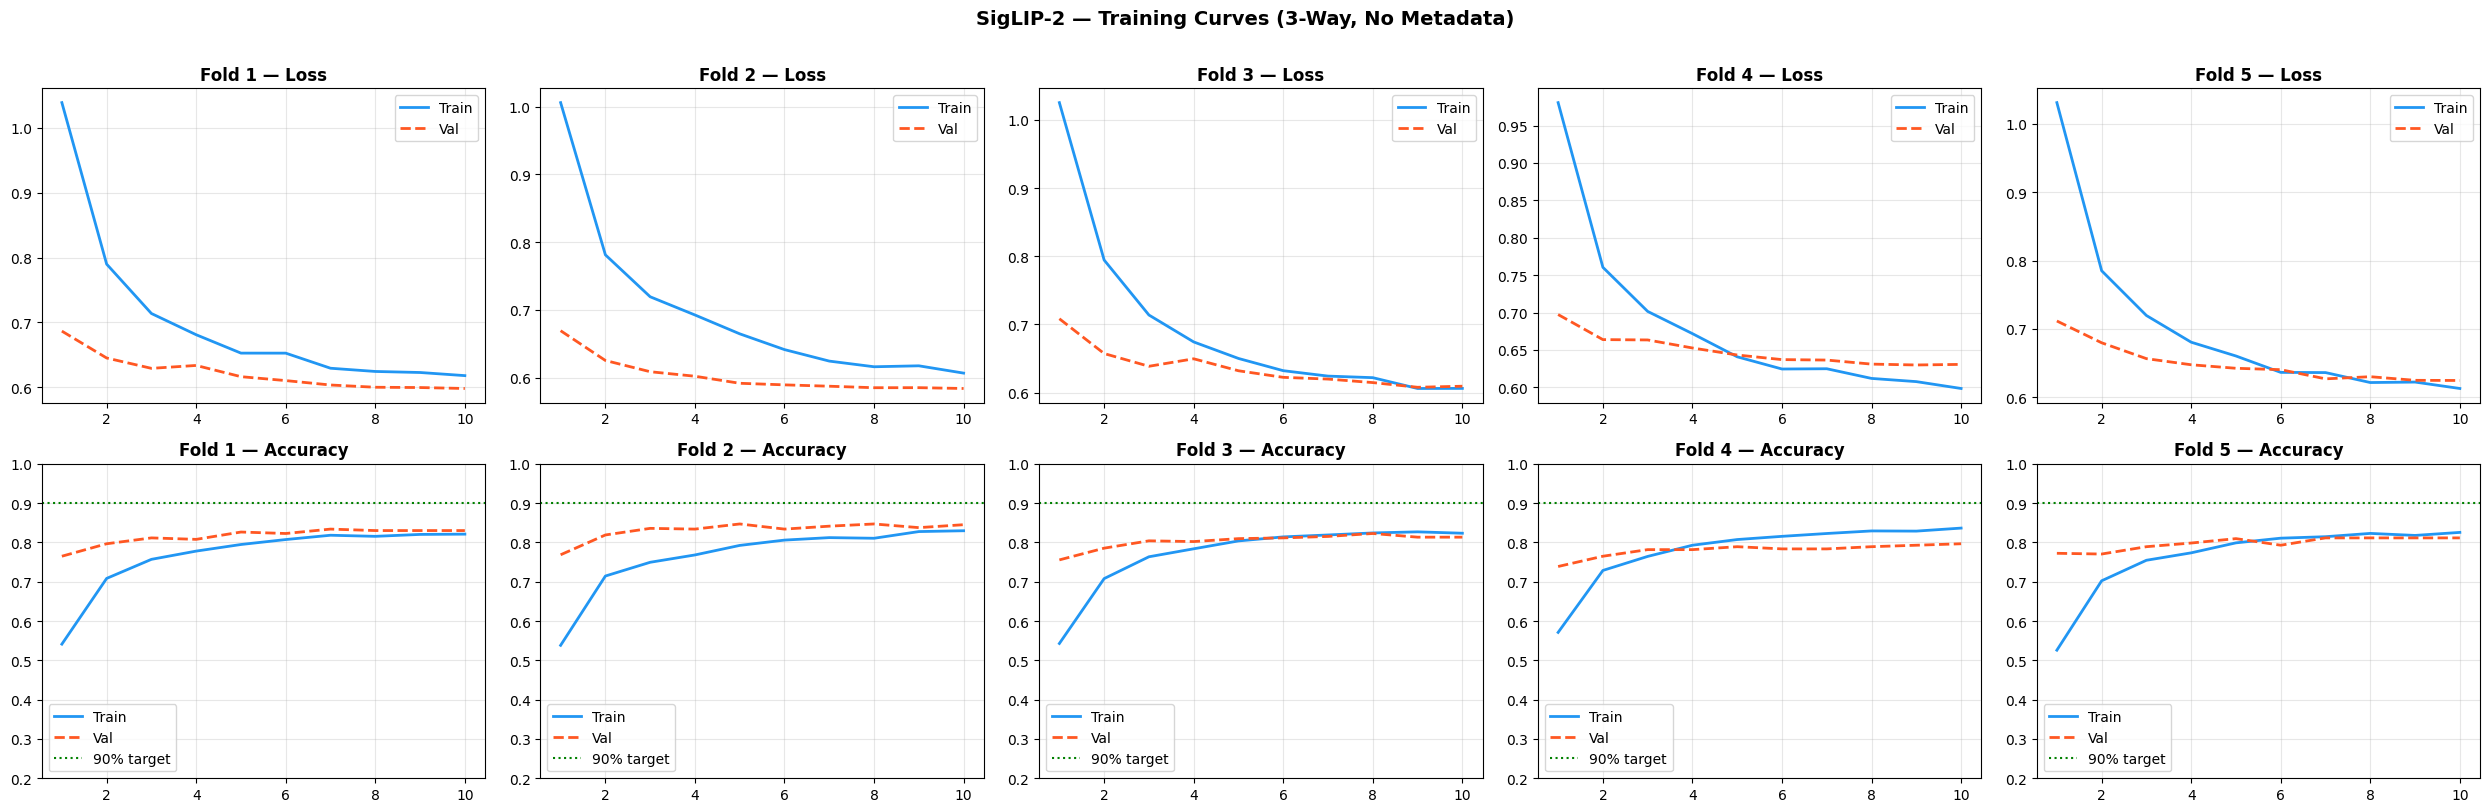

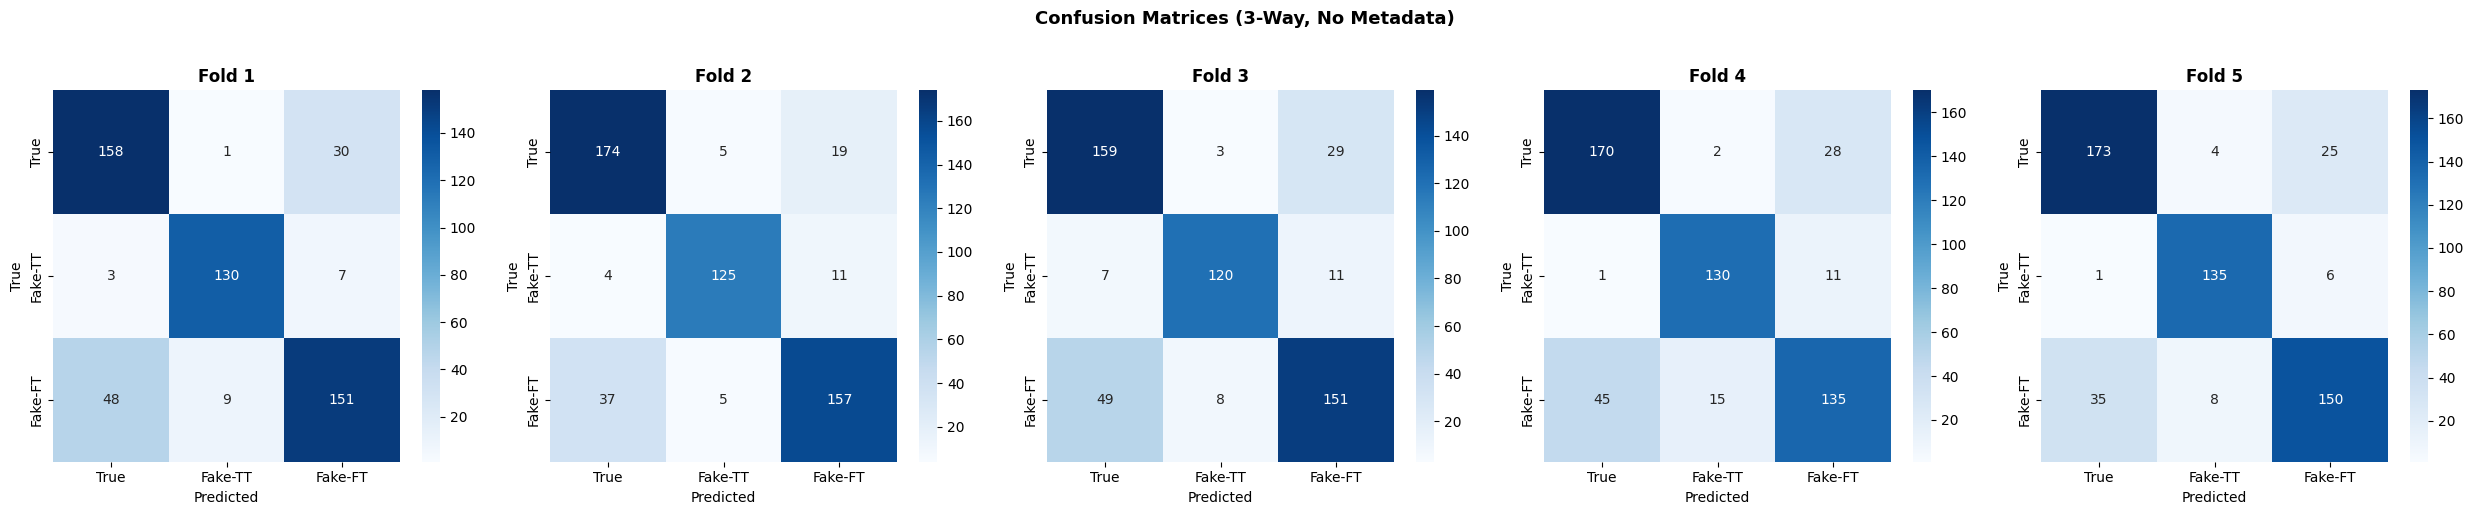

Visualizations saved to /kaggle/working/


In [17]:
# ── Cell 12: Generate Visualizations ──────────────────────────────────────────
plot_visualizations(all_history, all_cms)


In [18]:
# ── Cell 13: Final Summary (3-Way, No Metadata) ───────────────────────────────
print("\n" + "=" * 70)
print("  FINAL SUMMARY  —  3-Way Classification  (No Metadata)")
print("=" * 70)
print(f"  Model       : SigLIP-2 SO400M-384")
print(f"  Dataset     : Fakeddit ({NUM_SAMPLES} balanced samples)")
print(f"  Task        : 3-way ONLY  (2-way & 6-way CANCELLED)")
print(f"  Classes     : {LABEL_NAMES}")
print(f"  Metadata    : NONE  (pure text + image)")
print(f"  Fusion      : Bidirectional cross-attention (4-branch, 1024-d)")
print(f"  SWA         : {'enabled' if USE_SWA else 'disabled'}")
print()
print(f"  Performance (macro):")
print(f"    Mean Accuracy  : {summary['mean_accuracy']:.4f}")
print(f"    Mean F1 Macro  : {summary['mean_f1']:.4f}")
print(f"    Mean Precision : {summary['mean_precision']:.4f}")
print(f"    Mean Recall    : {summary['mean_recall']:.4f}")
print(f"    Mean Ovf Gap   : {summary['mean_ovf_gap']:+.4f}")
print()
acc_ok = summary["mean_accuracy"] >= 0.90
gap_ok = abs(summary["mean_ovf_gap"]) < 0.05
acc_msg = "TARGET MET" if acc_ok else ("NOT MET (gap %.4f)" % (0.90 - summary["mean_accuracy"]))
gap_msg = "OK" if gap_ok else "EXCEEDED"
print(f"  Target >= 90% Acc : {acc_msg}")
print(f"  Overfit Gap < 5%  : {gap_msg}")
print()
print(f"  Files saved to {OUTPUT_DIR}/:")
print(f"    siglip_3way_nometa_results.csv")
print(f"    training_curves_3way_nometa.png")
print(f"    confusion_matrices_3way_nometa.png")
print("\n" + "=" * 70)
print("  3-Way (No Metadata) training complete!")
print("=" * 70)



  FINAL SUMMARY  —  3-Way Classification  (No Metadata)
  Model       : SigLIP-2 SO400M-384
  Dataset     : Fakeddit (6000 balanced samples)
  Task        : 3-way ONLY  (2-way & 6-way CANCELLED)
  Classes     : ['True/Authentic', 'Fake-TrueText', 'Fake-FalseText']
  Metadata    : NONE  (pure text + image)
  Fusion      : Bidirectional cross-attention (4-branch, 1024-d)
  SWA         : enabled

  Performance (macro):
    Mean Accuracy  : 0.8261
    Mean F1 Macro  : 0.8340
    Mean Precision : 0.8354
    Mean Recall    : 0.8347
    Mean Ovf Gap   : +0.0004

  Target >= 90% Acc : NOT MET (gap 0.0739)
  Overfit Gap < 5%  : OK

  Files saved to /kaggle/working/:
    siglip_3way_nometa_results.csv
    training_curves_3way_nometa.png
    confusion_matrices_3way_nometa.png

  3-Way (No Metadata) training complete!
